# FEES: duración y diversificación

Ejecutar todas las celdas en orden. Se usan los datos congelados del repositorio, sin llamar a APIs de precios. La referencia cubre el bloque USD de **69%** de la asignación; no replica el FEES completo. Puts de cobre quedan excluidas y MBS conserva su peso estratégico.

En Colab, esta celda descarga el proyecto público si no encuentra los archivos. También puede subir `entrega_fees.zip` al runtime antes de ejecutar. Los datos, las reglas y los prompts de IA forman parte de la entrega.


In [1]:
from pathlib import Path
import io
import os
import zipfile
import requests

proyecto = Path.cwd()
if not (proyecto / "config.json").exists() and (proyecto.parent / "config.json").exists():
    proyecto = proyecto.parent
if not (proyecto / "config.json").exists():
    archivo = proyecto / "entrega_fees.zip"
    if archivo.exists():
        contenido = archivo.read_bytes()
    else:
        url = "https://github.com/eldiegoveliz/presentacionasset/archive/refs/heads/analisis-fees.zip"
        respuesta = requests.get(url, timeout=60)
        respuesta.raise_for_status()
        contenido = respuesta.content
    destino = proyecto / "proyecto_fees"
    with zipfile.ZipFile(io.BytesIO(contenido)) as z:
        z.extractall(destino)
    proyecto = next(destino.rglob("config.json")).parent
os.chdir(proyecto)
print("Archivos de trabajo:", proyecto)


Archivos de trabajo: /tmp/fees-limpio-b2xbj_4b


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## Preparación

El código siguiente proviene de `analisis.py`. `config.json` fija pesos y costos antes de comparar resultados. El análisis solo lee archivos locales. `verificar.py` comprueba integridad, cálculos y moneda.


In [3]:
"""Análisis exploratorio del bloque USD del FEES. Sin optimización de pesos."""
import json
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd()


### leer_config

Leer los supuestos guardados. No ajustarlos para favorecer un resultado.

In [4]:
def leer_config():
    return json.loads((RAIZ / "config.json").read_text())

### cargar_mensuales

Comprobar precios y distribuciones. Convertir cierres diarios a retornos mensuales sin interpolar.

In [5]:
def cargar_mensuales(config):
    """Fin de mes disponible; exigir meses completos y fechas comunes en los ETF."""
    series, calidad = {}, []
    indices = []
    for ticker in config["etfs"]:
        d = pd.read_csv(RAIZ / f"data/raw/{ticker}.csv", index_col=0, parse_dates=True)
        if d.index.has_duplicates or not d.index.is_monotonic_increasing or d.isna().any().any():
            raise ValueError(f"Fechas o valores inválidos: {ticker}")
        if (d[["cierre", "ajustado"]] <= 0).any().any():
            raise ValueError(f"Precios no positivos: {ticker}")
        d = d.loc[config["inicio_descarga"]:config["corte"]]
        indices.append(d.index)
        # Contrastar ajuste de Yahoo con precio + dividendo en la fecha ex-dividendo.
        reconstruido = (d.cierre + d.dividendo) / d.cierre.shift(1) - 1
        ajustado = d.ajustado.pct_change(fill_method=None)
        error = float((reconstruido - ajustado).abs().max())
        if error > 0.001:
            raise ValueError(f"Ajuste de dividendos de {ticker} difiere más de 10 pb: {error}")
        mensual = d.ajustado.resample("ME").last()
        fechas = pd.Series(d.index, index=d.index).resample("ME").last()
        if mensual.isna().any() or ((mensual.index - pd.DatetimeIndex(fechas)).days > 7).any():
            raise ValueError(f"Mes faltante o cierre alejado de fin de mes: {ticker}")
        series[ticker] = mensual
        calidad.append({"ticker": ticker, "filas": len(d), "primera": str(d.index.min().date()),
                        "ultima": str(d.index.max().date()), "dividendos": int((d.dividendo != 0).sum()),
                        "max_error_retorno_pb": error * 10000})
    if any(not i.equals(indices[0]) for i in indices[1:]):
        raise ValueError("Los ETF tienen fechas distintas. Revisar, no rellenar silenciosamente.")
    precios = pd.DataFrame(series)
    precios = precios.loc[:config["corte"]]
    if precios.isna().any().any():
        raise ValueError("Precios mensuales incompletos")
    retornos = precios.pct_change(fill_method=None).iloc[1:]
    esperados = pd.date_range(retornos.index.min(), pd.Timestamp(config["corte"]), freq="ME")
    if not retornos.index.equals(esperados):
        raise ValueError("Faltan meses hasta el corte configurado. No extender el período por suposición.")
    return retornos, pd.DataFrame(calidad).set_index("ticker")

### pesos_escenario

Mover una cantidad fija de IEF a SHY. Mantener las clases estratégicas y normalizar solo el bloque estudiado.

In [6]:
def pesos_escenario(config, traspaso):
    """Pesos sobre el fondo total; normalizar recién al calcular el bloque 69%."""
    w = pd.Series(config["pesos_fondo_usd"], dtype=float)
    w["IEF"] -= traspaso
    w["SHY"] += traspaso
    if (w < 0).any() or not np.isclose(w.sum(), 0.69):
        raise ValueError("Pesos negativos o bloque distinto de 69%")
    if not np.isclose(w["MBB"], 0.15) or not np.isclose(w["STIP"], 0.04) or not np.isclose(w["BIL"], 0.10):
        raise ValueError("Se alteró la asignación de clases fijada por la política")
    if not np.isclose(w[["SHY", "IEI", "IEF"]].sum(), 0.40):
        raise ValueError("La asignación de Treasuries debe mantenerse en 40%")
    return w

### cartera

Sumar pesos por retornos, rebalancear cada mes y descontar costos sobre compras más ventas.

In [7]:
def cartera(retornos, pesos, costo=0.0005):
    """Rebalanceo mensual; costo por cada dólar comprado o vendido, sin dividir por dos."""
    w = pesos / pesos.sum()
    r = retornos.loc[:, w.index]
    bruto = r.dot(w)
    # Pesos que quedan después de la rentabilidad del mes previo.
    despues = r.add(1).mul(w).div(1 + bruto, axis=0)
    transado = despues.shift(1).sub(w).abs().sum(axis=1)
    transado.iloc[0] = 1.0  # Compra inicial desde efectivo.
    neto = (1 - costo * transado) * (1 + bruto) - 1
    return neto

### riqueza_y_caida

Acumular retornos e incluir el capital inicial al medir pérdidas desde máximos.

In [8]:
def riqueza_y_caida(retornos):
    riqueza = (1 + retornos).cumprod()
    # El capital inicial es 1: incluirlo evita esconder una caída en el primer mes.
    maximo = riqueza.cummax().clip(lower=1)
    return riqueza, riqueza / maximo - 1

### metricas

Calcular retorno compuesto anual, volatilidad anual, mayor caída mensual y peor mes.

In [9]:
def metricas(retornos):
    _, caida = riqueza_y_caida(retornos)
    return pd.DataFrame({"retorno_anual_pct": ((1 + retornos).prod() ** (12 / len(retornos)) - 1) * 100,
                         "volatilidad_anual_pct": retornos.std(ddof=1) * np.sqrt(12) * 100,
                         "caida_max_mensual_pct": caida.min() * 100,
                         "peor_mes_pct": retornos.min() * 100})

### bootstrap_media

Remuestrear las diferencias en bloques de meses. No confundir el intervalo de medias con uno de CAGR.

In [10]:
def bootstrap_media(diferencia, bloque, repeticiones, semilla):
    """Mismos meses para ambas carteras; bloques circulares preservan dependencia local."""
    valores = np.asarray(diferencia)
    n = len(valores)
    rng = np.random.default_rng(semilla)
    inicios = rng.integers(0, n, size=(repeticiones, int(np.ceil(n / bloque))))
    indices = (inicios[:, :, None] + np.arange(bloque)) % n
    muestras = valores[indices.reshape(repeticiones, -1)[:, :n]]
    return np.quantile(muestras.mean(axis=1) * 12 * 100, [0.025, 0.975])

### ejecutar

Comparar todos los escenarios y períodos definidos. Guardar tablas, gráficos y sensibilidad sin elegir un ganador.

In [11]:
def ejecutar():
    config = leer_config()
    salida = RAIZ / "results"
    figuras = salida / "figuras"
    figuras.mkdir(parents=True, exist_ok=True)
    todos, calidad = cargar_mensuales(config)
    r = todos.loc[config["inicio_analisis"]:]
    calidad.to_csv(salida / "calidad_datos.csv")
    todos.to_csv(salida / "retornos_activos_mensuales.csv")
    pesos = pd.DataFrame({nombre: pesos_escenario(config, delta)
                         for nombre, delta in config["traspasos_ief_a_shy"].items()})
    pesos.to_csv(salida / "pesos_sobre_fondo.csv")
    portafolios = pd.DataFrame({nombre: cartera(r, pesos[nombre], config["costo_por_dolar_transado"])
                               for nombre in pesos})
    referencia = portafolios.iloc[:, 0]
    resumen = metricas(portafolios)
    resumen["diferencia_cagr_pp"] = resumen.retorno_anual_pct - resumen.retorno_anual_pct.iloc[0]
    # Diagnóstico del cambio en el bloque soberano 85%, suponiendo idéntico el resto.
    # Es TE realizado de una diferencia proxy; NO es TE ex ante del custodio.
    resumen["te_proxy_soberano_pb"] = [
        (r.SHY - r.IEF).std(ddof=1) * np.sqrt(12) * delta / 0.85 * 10000
        for delta in config["traspasos_ief_a_shy"].values()]
    resumen["filtro_te_realizado_25pb"] = np.where(resumen.te_proxy_soberano_pb <= 25, "pasa solo diagnostico", "supera 25 pb")
    resumen.to_csv(salida / "metricas.csv")
    portafolios.to_csv(salida / "retornos_carteras_mensuales.csv")

    # Sensibilidad sin cambiar los pesos, ni elegir el mejor período.
    sensibilidad = []
    for inicio, fin, periodo in [("2014", "2019", "2014-2019"), ("2020", "2021", "2020-2021"),
                                  ("2022", "2022", "2022"), ("2023", config["corte"], "2023-corte")]:
        sub = todos.loc[inicio:fin]
        carteras = pd.DataFrame({n: cartera(sub, pesos[n], config["costo_por_dolar_transado"]) for n in pesos})
        m = metricas(carteras)
        m["periodo"] = periodo
        m["meses"] = len(sub)
        sensibilidad.append(m.reset_index(names="cartera"))
    sensibilidad = pd.concat(sensibilidad, ignore_index=True)
    sensibilidad.to_csv(salida / "sensibilidad_periodos.csv", index=False)
    costos = []
    for costo in (0, config["costo_por_dolar_transado"], 0.001):
        m = metricas(pd.DataFrame({n: cartera(r, pesos[n], costo) for n in pesos}))
        m["costo_pb_por_dolar"] = costo * 10000
        costos.append(m.reset_index(names="cartera"))
    pd.concat(costos).to_csv(salida / "sensibilidad_costos.csv", index=False)

    incertidumbre = []
    for nombre in portafolios.columns[1:]:
        for bloque in (3, 6, 12):
            delta = portafolios[nombre] - referencia
            inferior, superior = bootstrap_media(delta, bloque, config["bootstrap_repeticiones"], config["semilla"])
            incertidumbre.append({"cartera": nombre, "bloque_meses": bloque,
                                  "media_anualizada_pp": delta.mean() * 12 * 100,
                                  "ic95_inferior_pp": inferior, "ic95_superior_pp": superior})
    incertidumbre = pd.DataFrame(incertidumbre)
    incertidumbre.to_csv(salida / "incertidumbre.csv", index=False)

    correlaciones = []
    for inicio, fin, periodo in [("2014", "2019", "2014-2019"), ("2020", "2021", "2020-2021"),
                                  ("2022", "2022", "2022"), ("2023", config["corte"], "2023-corte")]:
        sub = todos.loc[inicio:fin]
        for bono in ("SHY", "IEI", "IEF", "MBB"):
            correlaciones.append({"periodo": periodo, "bono": bono, "meses": len(sub),
                                   "correlacion_SPY": sub[bono].corr(sub.SPY),
                                   "ambos_negativos_meses": int(((sub[bono] < 0) & (sub.SPY < 0)).sum()),
                                   "retorno_medio_bono_SPY_negativo_pct": sub.loc[sub.SPY < 0, bono].mean() * 100})
    correlaciones = pd.DataFrame(correlaciones)
    correlaciones.to_csv(salida / "correlaciones.csv", index=False)
    filas_html = []
    for fila in correlaciones.loc[correlaciones.bono == "IEF"].itertuples():
        valor = fila.correlacion_SPY
        ancho = abs(valor) * 50
        izquierda = 50 if valor >= 0 else 50 - ancho
        color = "--chart-1" if valor >= 0 else "--chart-2"
        filas_html.append(f'<div class="fila"><span>{fila.periodo}</span>'
                          f'<div class="pista"><i class="cero"></i><i class="barra" '
                          f'style="left:{izquierda:.2f}%;width:{ancho:.2f}%;background:var({color})"></i></div>'
                          f'<strong>{valor:+.2f}</strong></div>')
    html = '''<!doctype html><html lang="es"><meta charset="utf-8">
<style>:root{font-family:var(--font-sans)}body{margin:0;color:var(--foreground)}
h3{font-size:17px;margin:0 0 8px}.nota{font-size:13px;color:var(--muted-foreground);line-height:1.5}
.fila{display:grid;grid-template-columns:105px minmax(0,1fr) 52px;align-items:center;gap:10px;height:42px;font-size:14px}
.fila strong{text-align:right;font-family:var(--font-mono);font-size:14px}
.pista{position:relative;height:26px;background:var(--secondary);border-radius:var(--radius)}
.cero{position:absolute;left:50%;height:100%;width:1px;background:var(--foreground);opacity:.4}
.barra{position:absolute;top:4px;height:18px;border-radius:3px}
.eje{margin:0 62px 8px 115px;display:flex;justify-content:space-between;font-size:11px;color:var(--muted-foreground)}
</style><body><h3>Bonos y acciones: la relación cambió según el período</h3>
<p class="nota">Correlación de retornos mensuales: Treasury 7–10 años (IEF) con S&amp;P 500 (SPY).</p>
<div class="eje"><span>−1</span><span>0</span><span>+1</span></div>''' + "".join(filas_html) + '''
<p class="nota">2023–corte termina en octubre de 2026. 2022 contiene solo 12 meses.
Correlación positiva no demuestra ausencia total de diversificación. SPY no integra las carteras.
Fuente: Yahoo, cálculos de analisis.py; results/correlaciones.csv.</p></body></html>'''
    (salida / "resumen.html").write_text(html)

    fx = pd.read_csv(RAIZ / f"data/raw/{config['tipo_cambio']}.csv", index_col=0, parse_dates=True).cierre
    fx_mensual = fx.resample("ME").last().loc[todos.index.min() - pd.offsets.MonthEnd(1):config["corte"]]
    fechas_fx = pd.Series(fx.dropna().index, index=fx.dropna().index).resample("ME").last()
    if fx_mensual.isna().any() or ((fechas_fx.index - pd.DatetimeIndex(fechas_fx)).days > 7).any():
        raise ValueError("Faltan cierres de FX. No rellenar.")
    cambio = fx_mensual.pct_change(fill_method=None).reindex(r.index)
    if cambio.isna().any():
        raise ValueError("FX sin alinear con carteras")
    clp = (1 + portafolios).mul(1 + cambio, axis=0) - 1
    clp.to_csv(salida / "retornos_carteras_clp.csv")
    metricas(clp).to_csv(salida / "metricas_clp.csv")

    plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2})
    riqueza, caida = riqueza_y_caida(portafolios)
    # Mostrar también el capital inicial antes del primer retorno.
    origen = portafolios.index[0] - pd.offsets.MonthEnd(1)
    riqueza_grafico = pd.concat([pd.DataFrame(1., index=[origen], columns=riqueza.columns), riqueza])
    ax = (100 * riqueza_grafico).plot(title="Bloque USD (69% del FEES): riqueza con distribuciones")
    ax.set_ylabel("USD por 100 iniciales"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "riqueza.png", dpi=160); plt.close()
    ax = (100 * caida).plot(title="Caídas desde el máximo: cierres mensuales del bloque USD")
    ax.set_ylabel("Caída (%)"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "caidas.png", dpi=160); plt.close()
    movil = pd.DataFrame({b: todos[b].rolling(12).corr(todos.SPY) for b in ("SHY", "IEI", "IEF", "MBB")})
    movil.to_csv(salida / "correlacion_movil_12m.csv")
    ax = movil.plot(title="Correlación con SPY: retornos mensuales, ventana de 12 meses", ylim=(-1, 1))
    ax.axhline(0, color="black", linewidth=0.7); ax.set_ylabel("Correlación"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "correlacion.png", dpi=160); plt.close()
    tasas = pd.concat([pd.read_csv(RAIZ / f"data/raw/{s}.csv", index_col=0, parse_dates=True)[s]
                       for s in ("DGS2", "DGS10")], axis=1)
    ax = tasas.loc[config["inicio_analisis"]:].plot(title="Contexto FRED: tasas del Tesoro, no retornos")
    ax.set_ylabel("Tasa anual (%)"); ax.set_xlabel("")
    plt.tight_layout(); plt.savefig(figuras / "tasas.png", dpi=160); plt.close()

    informe(config, resumen, correlaciones, incertidumbre, sensibilidad, metricas(clp), len(r), r.index[-1])
    print(resumen.round(3).to_string())
    print(f"\n{len(r)} meses. Informe: {salida / 'informe.md'}")
    return resumen

### informe

Escribir el mini informe directamente desde las tablas calculadas. Los límites de las conclusiones quedan junto a los resultados.

In [12]:
def informe(config, resumen, correlaciones, incertidumbre, sensibilidad, clp, n, ultima):
    corr = correlaciones.pivot(index="periodo", columns="bono", values="correlacion_SPY")
    base = resumen.iloc[0]
    ejemplo = resumen.loc["Duracion -2 pp"]
    intervalo = incertidumbre.loc[(incertidumbre.cartera == "Duracion -2 pp") &
                                  (incertidumbre.bloque_meses == 6)].iloc[0]
    exceso = resumen.loc[resumen.te_proxy_soberano_pb > 25]
    descarte = "; ".join(f"{nombre}: {fila.te_proxy_soberano_pb:.2f} pb" for nombre, fila in exceso.iterrows())
    texto = f"""# FEES: resultados exploratorios para el Comité Financiero

Ejecución reproducible: `python analisis.py`. Corte solicitado: {config['corte']}; último cierre mensual: {ultima.date()}; {n} retornos mensuales desde enero de 2020. Consulta de reglas: 8 de noviembre de 2026.

## Qué permite concluir este ejercicio

La política defensiva del FEES es coherente con disponer de recursos líquidos durante estrés fiscal. Este análisis parcial no prueba que su cartera completa sea óptima. Mantener el 15% estratégico de MBS y excluir puts de cobre respeta las directrices consultadas. Acortar duración merece evaluar el presupuesto de riesgo ex ante; estos resultados por sí solos no autorizan una operación.

La referencia es una **aproximación del bloque USD, que representa 69% de la asignación estratégica**. No es el retorno efectivo del FEES ni su benchmark oficial. No se modelan Europa (19%), Japón (9%) ni China (3%). Los resultados se expresan por 100 invertidos en ese bloque, sin multiplicarlos y presentarlos como retornos del fondo completo.

## Las cuatro ideas

1. **Bonos y acciones:** la tabla siguiente muestra cuándo aumentó la correlación y cuánto depende del bono y del período. Correlación positiva no equivale a ausencia total de diversificación. SPY es solo diagnóstico y no integra ninguna cartera.
2. **Puts sobre futuros del cobre:** excluidas porque no figuran en la lista de instrumentos elegibles. No se simulan primas ni se presenta un backtest de opciones inexistente.
3. **Treasuries más cortos:** se comparan traspasos de 1, 2 y 4 puntos porcentuales del fondo desde la proxy 7–10 años a 1–3 años. Se conservan el 40% de Treasuries y los demás pesos estratégicos. El tracking error realizado solo permite un diagnóstico preliminar.
4. **Más o menos MBS:** no se cambia el 15% de la asignación estratégica. Las directrices no ofrecen una banda táctica general para esta decisión. Una investigación sobre un cambio de política queda fuera de la restricción del usuario.

## Retorno y riesgo del bloque USD

Porcentajes anuales salvo caída máxima y peor mes. La caída se mide en cierres mensuales e incluye el capital inicial. La diferencia es entre retornos geométricos anualizados. El TE es un diagnóstico anualizado en puntos base sobre el bloque soberano 85%, suponiendo idéntico el resto de las exposiciones.

{resumen.round(3).to_markdown()}

La referencia devuelve {base.retorno_anual_pct:.2f}% anual, con volatilidad {base.volatilidad_anual_pct:.2f}% y caída máxima mensual {base.caida_max_mensual_pct:.2f}%. Revisar todas las alternativas; no escoger la mejor como pronóstico. Incluso un TE realizado inferior a 25 pb **no demuestra** cumplimiento ex ante, ni elegibilidad legal de ETFs.

Como ejemplo intermedio fijado en el diseño, el traspaso de 2 pp devuelve {ejemplo.retorno_anual_pct:.2f}% anual y reduce la caída máxima mensual a {ejemplo.caida_max_mensual_pct:.2f}%. Su mejora de CAGR es {ejemplo.diferencia_cagr_pp * 100:.2f} pb anuales del bloque USD. El intervalo de la diferencia de medias, con bloques de seis meses, va de {intervalo.ic95_inferior_pp:.3f} a {intervalo.ic95_superior_pp:.3f} pp anuales e incluye cero. La evidencia no basta para recomendar el cambio por retorno esperado. Se descartan preliminarmente los escenarios que superan el diagnóstico de 25 pb: {descarte or 'ninguno'}. Los demás siguen requiriendo comprobación oficial ex ante.

![Evolución de riqueza](figuras/riqueza.png)

![Caídas mensuales](figuras/caidas.png)

## Correlación de bonos con acciones

Correlaciones entre retornos totales mensuales en USD. Tamaños de muestra, meses con pérdidas conjuntas y retornos de bonos cuando SPY cae están en `correlaciones.csv`. La muestra de 2022 solo tiene 12 meses.

{corr.round(3).to_markdown()}

![Correlación móvil](figuras/correlacion.png)

## Sensibilidad e incertidumbre

Las ventanas se fijan por calendario, sin buscar el punto de quiebre más favorable. Cada ventana reinicia la inversión y cobra su compra inicial. Son comparaciones retrospectivas; los datos recientes ya inspiraron las hipótesis. No constituyen una prueba fuera de muestra.

{sensibilidad.round(3).to_markdown(index=False)}

Bootstrap pareado por bloques circulares, {config['bootstrap_repeticiones']} repeticiones y semilla {config['semilla']}. Los intervalos describen la **diferencia de medias mensuales multiplicada por 12**, en puntos porcentuales anuales; no la diferencia de CAGR. Se muestran bloques de 3, 6 y 12 meses. Son intervalos individuales del 95%, sin ajuste por comparaciones múltiples. No se usan para declarar ganadores ni significancia conjunta.

{incertidumbre.round(3).to_markdown(index=False)}

## Moneda relevante para el Fisco

Conversión ilustrativa: `(1 + retorno USD) × (1 + variación CLP por USD) − 1`, usando CLP=X (USD/CLP) de Yahoo. El cierre cambiario disponible puede diferir del horario del ETF y del dólar observado del Banco Central. Esto muestra la importancia del peso, pero no mide la cobertura de retiros fiscales ni de ingresos del cobre.

{clp.round(3).to_markdown()}

## Supuestos que afectan la interpretación

- La distribución actual se aplica al pasado como contrafactual, incluso antes de su implementación en noviembre de 2023. No se afirma que regía en 2020.
- Treasuries: un tercio de cada tramo SHY, IEI e IEF dentro del 40%, supuesto explícito. No son los pesos por capitalización del índice oficial. STIP cubre 0–5 años y no replica TIPS 1–10 años. MBB y BIL tampoco replican exactamente sus comparadores oficiales. Los ETFs son instrumentos de medición, no órdenes propuestas para el FEES.
- Cierres ajustados de Yahoo aproximan retorno total con distribuciones reinvertidas, netos de gastos internos del ETF. La validación contrasta cada retorno diario con cierre y distribución. No se suman dividendos otra vez.
- Rebalanceo mensual a pesos fijos, sin aportes ni retiros, costo de {config['costo_por_dolar_transado'] * 10000:.0f} pb por dólar comprado o vendido, incluida compra inicial. No hay impuesto, spread dinámico, deslizamiento ni comisión oficial FEES. `sensibilidad_costos.csv` muestra 0, 5 y 10 pb. La norma exige al menos un rebalanceo anual sin flujos, no este calendario mensual.
- El TE proxy usa la volatilidad histórica de la diferencia SHY–IEF, multiplicada por el traspaso y dividida por 85%. No incorpora el riesgo de réplica de la referencia frente al índice oficial. No reemplaza la matriz de riesgo ni el cálculo diario del custodio.
- Frecuencia mensual: volatilidad anualizada con raíz de 12 y observaciones equiponderadas. Los máximos intrames y los costos de liquidación en crisis pueden ser mayores.
- Cambios en tasas FRED solo sirven de contexto; nunca se usan como retornos de bonos. Datos originales, fechas y SHA-256 están en `data/metadatos.json`.

## Fuentes y archivos para revisar

[Política y asignación oficial](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion), [directrices vigentes, oficio 1085/2023](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion/pauta-de-inversion-vigente), [composición oficial de septiembre de 2026](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/informacion-financiera/composicion-actual), [Yahoo USD/CLP](https://finance.yahoo.com/quote/CLP=X/), [FRED DGS2](https://fred.stlouisfed.org/series/DGS2), [FRED DGS10](https://fred.stlouisfed.org/series/DGS10). Los enlaces de cada descarga Yahoo están en el manifiesto. Las reglas con páginas y la tabla de proxies están en `docs/reglas-fees.md` y `docs/metodologia.md`.

Este trabajo cubre FEES parcialmente. El FRP sigue pendiente y el encargo del curso requiere ambos fondos. La revisión y defensa del equipo, el memo final y las firmas del anexo de IA siguen pendientes.
"""
    (RAIZ / "results/informe.md").write_text(texto)

## Ejecutar el análisis

Todas las cifras del informe salen de esta ejecución.

In [13]:
resumen = ejecutar()
display(resumen.round(3))

                      retorno_anual_pct  volatilidad_anual_pct  caida_max_mensual_pct  peor_mes_pct  diferencia_cagr_pp  te_proxy_soberano_pb filtro_te_realizado_25pb
Referencia proxy USD              1.268                  4.018                -11.088        -2.965               0.000                 0.000    pasa solo diagnostico
Duracion -1 pp                    1.297                  3.939                -10.852        -2.914               0.029                 6.783    pasa solo diagnostico
Duracion -2 pp                    1.326                  3.861                -10.617        -2.863               0.058                13.566    pasa solo diagnostico
Duracion -4 pp                    1.384                  3.704                -10.144        -2.760               0.115                27.132             supera 25 pb

82 meses. Informe: /tmp/fees-limpio-b2xbj_4b/results/informe.md


,retorno_anual_pct,volatilidad_anual_pct,caida_max_mensual_pct,peor_mes_pct,diferencia_cagr_pp,te_proxy_soberano_pb,filtro_te_realizado_25pb
Referencia proxy USD,1.268,4.018,-11.088,-2.965,0.000,0.000,pasa solo diagnostico
Duracion -1 pp,1.297,3.939,-10.852,-2.914,0.029,6.783,pasa solo diagnostico
Duracion -2 pp,1.326,3.861,-10.617,-2.863,0.058,13.566,pasa solo diagnostico
Duracion -4 pp,1.384,3.704,-10.144,-2.760,0.115,27.132,supera 25 pb


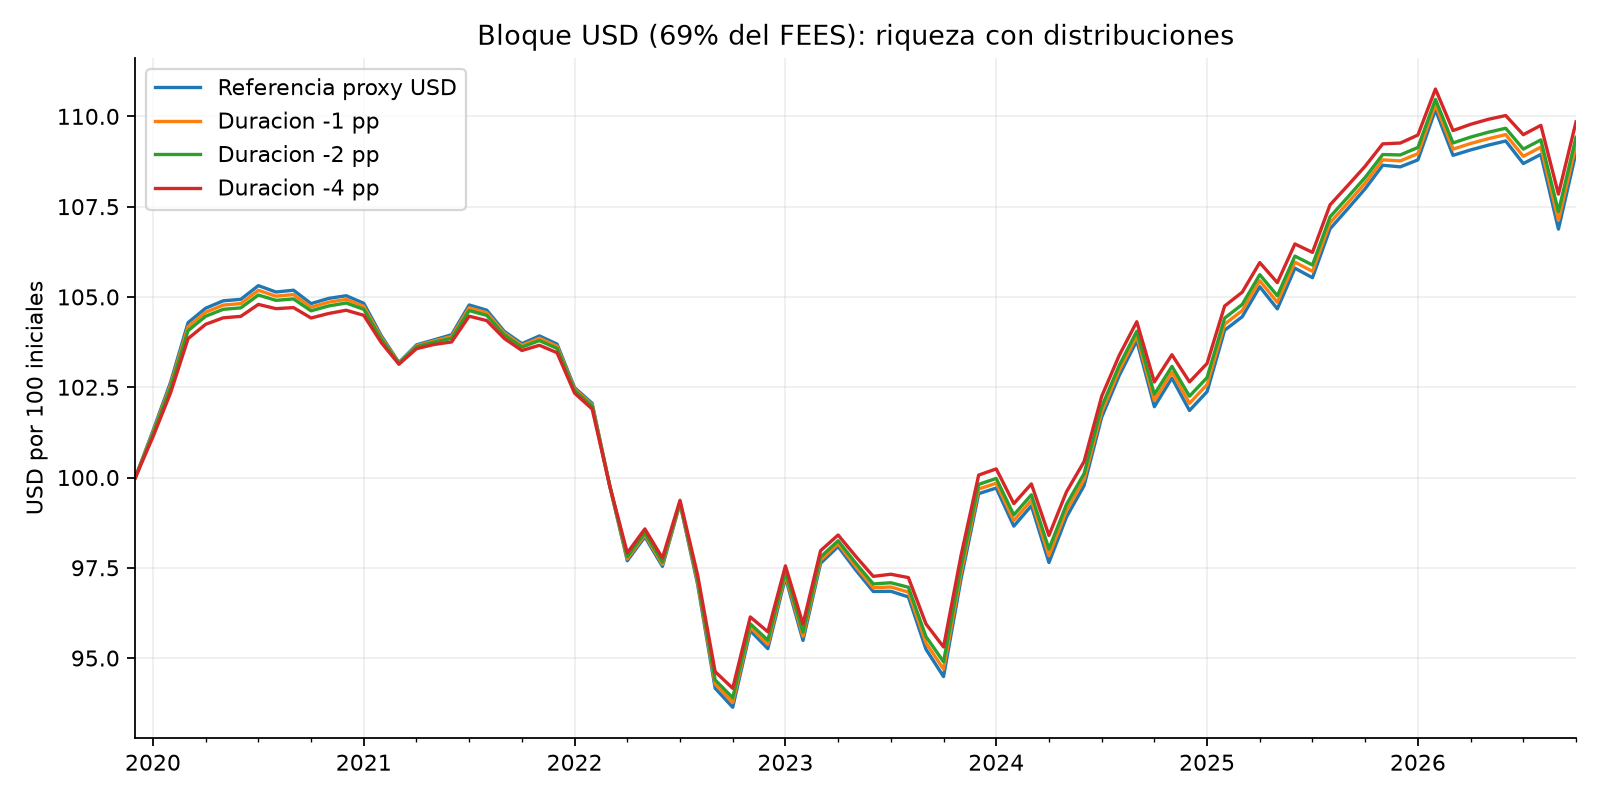

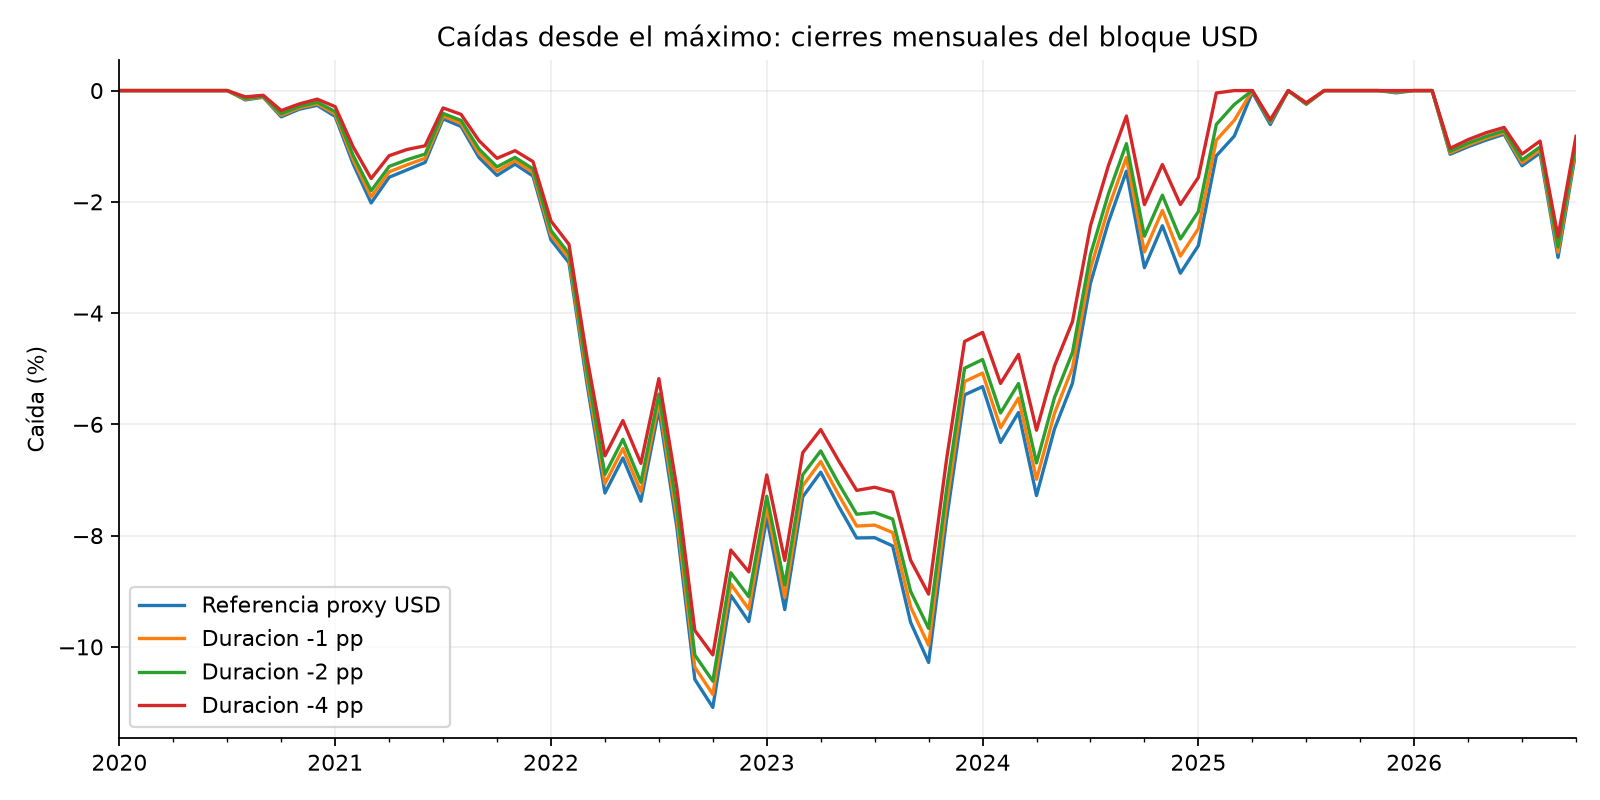

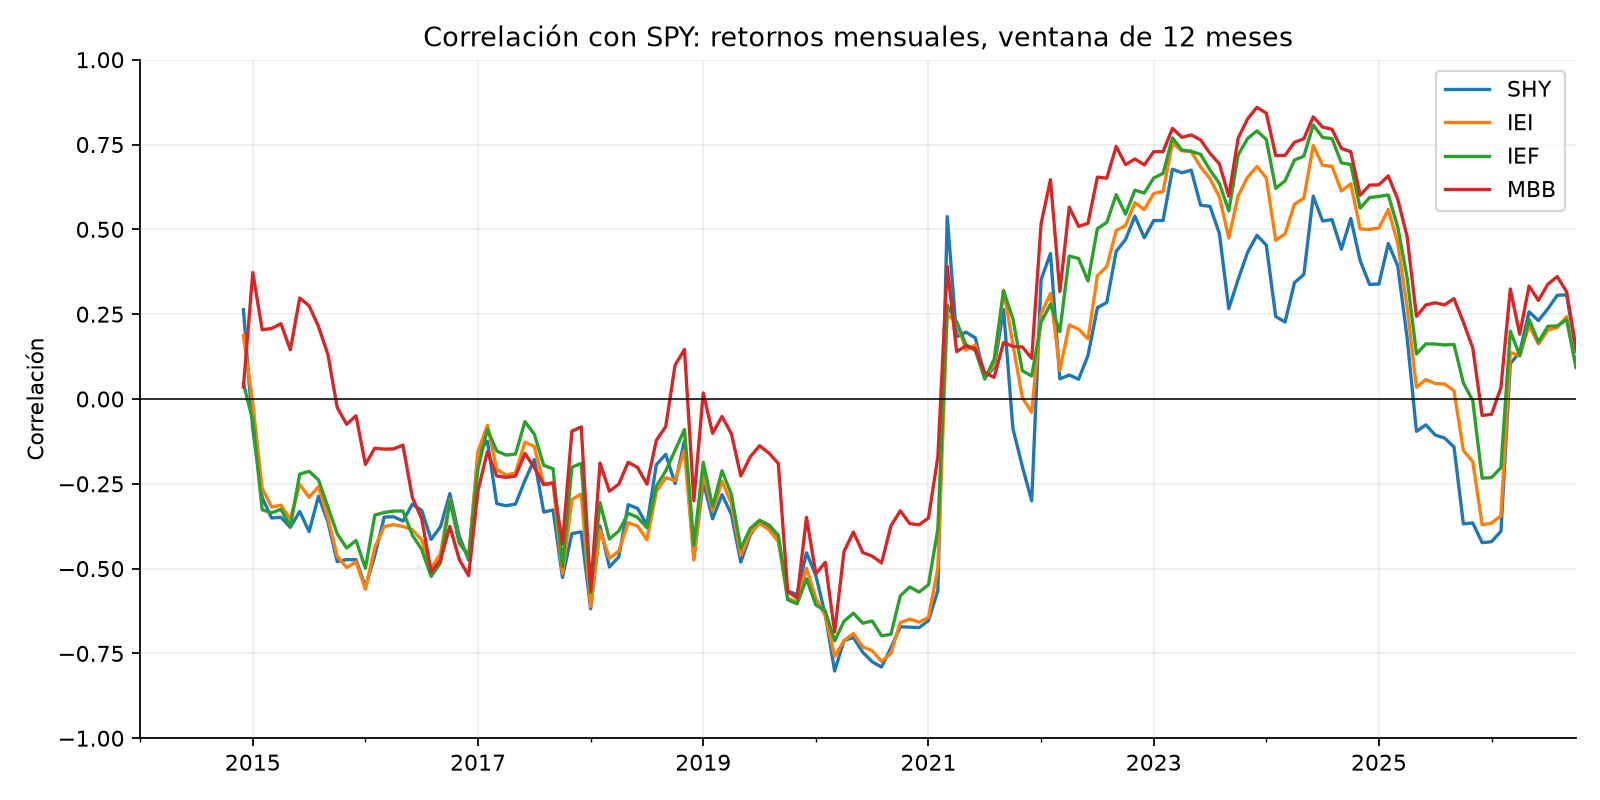

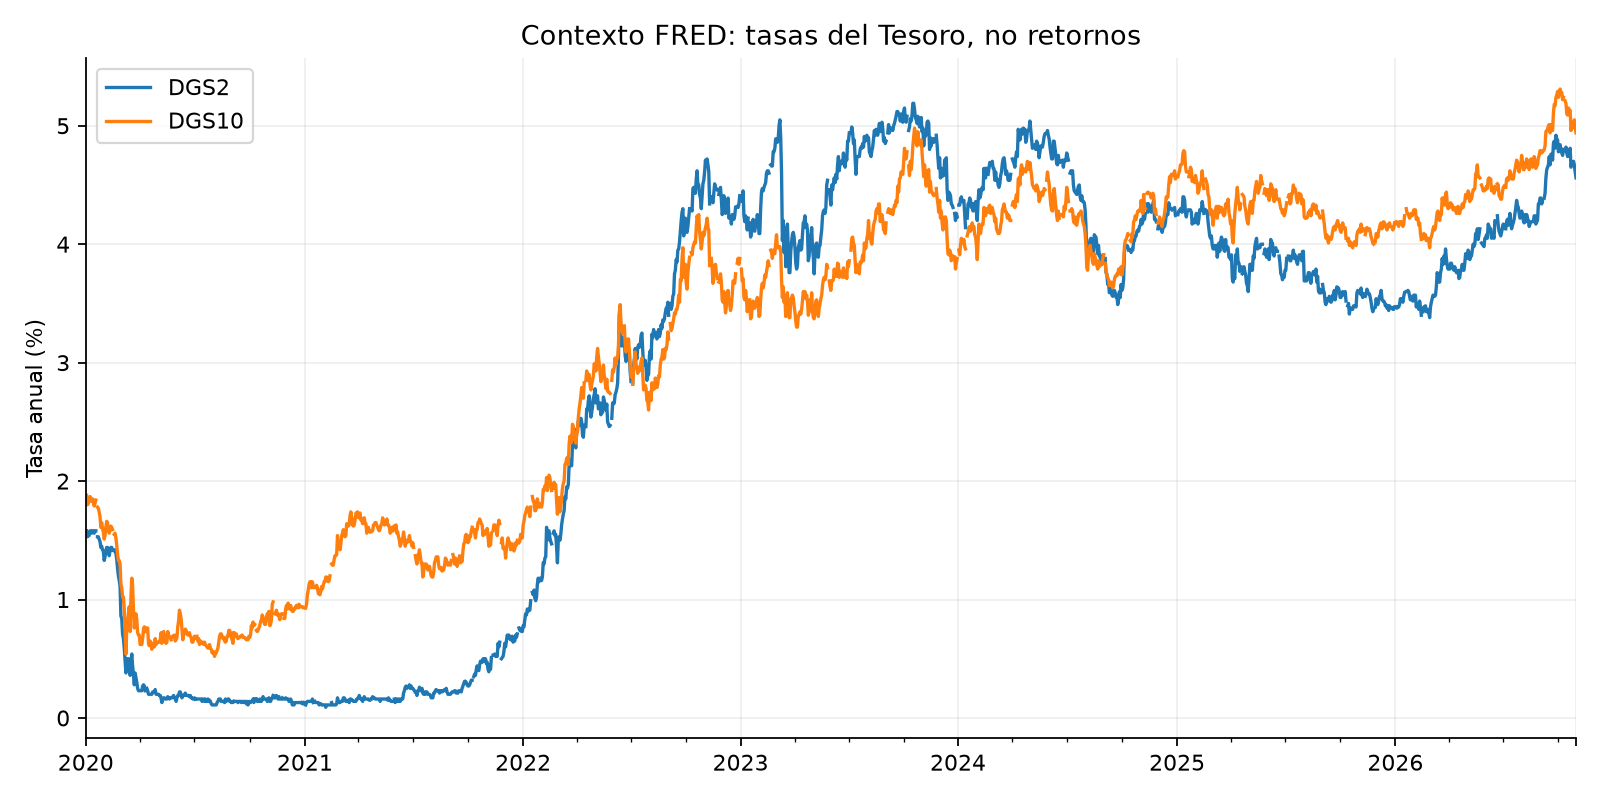

# FEES: resultados exploratorios para el Comité Financiero

Ejecución reproducible: `python analisis.py`. Corte solicitado: 2026-10-31; último cierre mensual: 2026-10-31; 82 retornos mensuales desde enero de 2020. Consulta de reglas: 8 de noviembre de 2026.

## Qué permite concluir este ejercicio

La política defensiva del FEES es coherente con disponer de recursos líquidos durante estrés fiscal. Este análisis parcial no prueba que su cartera completa sea óptima. Mantener el 15% estratégico de MBS y excluir puts de cobre respeta las directrices consultadas. Acortar duración merece evaluar el presupuesto de riesgo ex ante; estos resultados por sí solos no autorizan una operación.

La referencia es una **aproximación del bloque USD, que representa 69% de la asignación estratégica**. No es el retorno efectivo del FEES ni su benchmark oficial. No se modelan Europa (19%), Japón (9%) ni China (3%). Los resultados se expresan por 100 invertidos en ese bloque, sin multiplicarlos y presentarlos como retornos del fondo completo.

## Las cuatro ideas

1. **Bonos y acciones:** la tabla siguiente muestra cuándo aumentó la correlación y cuánto depende del bono y del período. Correlación positiva no equivale a ausencia total de diversificación. SPY es solo diagnóstico y no integra ninguna cartera.
2. **Puts sobre futuros del cobre:** excluidas porque no figuran en la lista de instrumentos elegibles. No se simulan primas ni se presenta un backtest de opciones inexistente.
3. **Treasuries más cortos:** se comparan traspasos de 1, 2 y 4 puntos porcentuales del fondo desde la proxy 7–10 años a 1–3 años. Se conservan el 40% de Treasuries y los demás pesos estratégicos. El tracking error realizado solo permite un diagnóstico preliminar.
4. **Más o menos MBS:** no se cambia el 15% de la asignación estratégica. Las directrices no ofrecen una banda táctica general para esta decisión. Una investigación sobre un cambio de política queda fuera de la restricción del usuario.

## Retorno y riesgo del bloque USD

Porcentajes anuales salvo caída máxima y peor mes. La caída se mide en cierres mensuales e incluye el capital inicial. La diferencia es entre retornos geométricos anualizados. El TE es un diagnóstico anualizado en puntos base sobre el bloque soberano 85%, suponiendo idéntico el resto de las exposiciones.

|                      |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |   diferencia_cagr_pp |   te_proxy_soberano_pb | filtro_te_realizado_25pb   |
|:---------------------|--------------------:|------------------------:|------------------------:|---------------:|---------------------:|-----------------------:|:---------------------------|
| Referencia proxy USD |               1.268 |                   4.018 |                 -11.088 |         -2.965 |                0     |                  0     | pasa solo diagnostico      |
| Duracion -1 pp       |               1.297 |                   3.939 |                 -10.852 |         -2.914 |                0.029 |                  6.783 | pasa solo diagnostico      |
| Duracion -2 pp       |               1.326 |                   3.861 |                 -10.617 |         -2.863 |                0.058 |                 13.566 | pasa solo diagnostico      |
| Duracion -4 pp       |               1.384 |                   3.704 |                 -10.144 |         -2.76  |                0.115 |                 27.132 | supera 25 pb               |

La referencia devuelve 1.27% anual, con volatilidad 4.02% y caída máxima mensual -11.09%. Revisar todas las alternativas; no escoger la mejor como pronóstico. Incluso un TE realizado inferior a 25 pb **no demuestra** cumplimiento ex ante, ni elegibilidad legal de ETFs.

Como ejemplo intermedio fijado en el diseño, el traspaso de 2 pp devuelve 1.33% anual y reduce la caída máxima mensual a -10.62%. Su mejora de CAGR es 5.78 pb anuales del bloque USD. El intervalo de la diferencia de medias, con bloques de seis meses, va de -0.065 a 0.157 pp anuales e incluye cero. La evidencia no basta para recomendar el cambio por retorno esperado. Se descartan preliminarmente los escenarios que superan el diagnóstico de 25 pb: Duracion -4 pp: 27.13 pb. Los demás siguen requiriendo comprobación oficial ex ante.

![Evolución de riqueza](figuras/riqueza.png)

![Caídas mensuales](figuras/caidas.png)

## Correlación de bonos con acciones

Correlaciones entre retornos totales mensuales en USD. Tamaños de muestra, meses con pérdidas conjuntas y retornos de bonos cuando SPY cae están en `correlaciones.csv`. La muestra de 2022 solo tiene 12 meses.

| periodo    |    IEF |    IEI |    MBB |    SHY |
|:-----------|-------:|-------:|-------:|-------:|
| 2014-2019  | -0.338 | -0.347 | -0.165 | -0.322 |
| 2020-2021  | -0.373 | -0.477 | -0.205 | -0.577 |
| 2022       |  0.607 |  0.558 |  0.69  |  0.475 |
| 2023-corte |  0.44  |  0.359 |  0.519 |  0.249 |

![Correlación móvil](figuras/correlacion.png)

## Sensibilidad e incertidumbre

Las ventanas se fijan por calendario, sin buscar el punto de quiebre más favorable. Cada ventana reinicia la inversión y cobra su compra inicial. Son comparaciones retrospectivas; los datos recientes ya inspiraron las hipótesis. No constituyen una prueba fuera de muestra.

| cartera              |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct | periodo    |   meses |
|:---------------------|--------------------:|------------------------:|------------------------:|---------------:|:-----------|--------:|
| Referencia proxy USD |               2.239 |                   2.207 |                  -2.403 |         -1.776 | 2014-2019  |      72 |
| Duracion -1 pp       |               2.2   |                   2.145 |                  -2.316 |         -1.721 | 2014-2019  |      72 |
| Duracion -2 pp       |               2.161 |                   2.083 |                  -2.229 |         -1.667 | 2014-2019  |      72 |
| Duracion -4 pp       |               2.082 |                   1.959 |                  -2.057 |         -1.558 | 2014-2019  |      72 |
| Referencia proxy USD |               1.831 |                   2.126 |                  -2.02  |         -0.859 | 2020-2021  |      24 |
| Duracion -1 pp       |               1.801 |                   2.061 |                  -1.911 |         -0.825 | 2020-2021  |      24 |
| Duracion -2 pp       |               1.772 |                   1.998 |                  -1.801 |         -0.792 | 2020-2021  |      24 |
| Duracion -4 pp       |               1.713 |                   1.871 |                  -1.582 |         -0.725 | 2020-2021  |      24 |
| Referencia proxy USD |              -8.18  |                   5.631 |                  -9.745 |         -2.965 | 2022       |      12 |
| Duracion -1 pp       |              -8.014 |                   5.526 |                  -9.566 |         -2.914 | 2022       |      12 |
| Duracion -2 pp       |              -7.848 |                   5.422 |                  -9.387 |         -2.863 | 2022       |      12 |
| Duracion -4 pp       |              -7.516 |                   5.213 |                  -9.027 |         -2.76  | 2022       |      12 |
| Referencia proxy USD |               3.563 |                   4.056 |                  -3.672 |         -1.898 | 2023-corte |      46 |
| Duracion -1 pp       |               3.582 |                   3.977 |                  -3.541 |         -1.858 | 2023-corte |      46 |
| Duracion -2 pp       |               3.602 |                   3.898 |                  -3.411 |         -1.817 | 2023-corte |      46 |
| Duracion -4 pp       |               3.64  |                   3.74  |                  -3.15  |         -1.736 | 2023-corte |      46 |

Bootstrap pareado por bloques circulares, 2000 repeticiones y semilla 20261108. Los intervalos describen la **diferencia de medias mensuales multiplicada por 12**, en puntos porcentuales anuales; no la diferencia de CAGR. Se muestran bloques de 3, 6 y 12 meses. Son intervalos individuales del 95%, sin ajuste por comparaciones múltiples. No se usan para declarar ganadores ni significancia conjunta.

| cartera        |   bloque_meses |   media_anualizada_pp |   ic95_inferior_pp |   ic95_superior_pp |
|:---------------|---------------:|----------------------:|-------------------:|-------------------:|
| Duracion -1 pp |              3 |                 0.025 |             -0.038 |              0.092 |
| Duracion -1 pp |              6 |                 0.025 |             -0.033 |              0.079 |
| Duracion -1 pp |             12 |                 0.025 |             -0.026 |              0.077 |
| Duracion -2 pp |              3 |                 0.051 |             -0.076 |              0.185 |
| Duracion -2 pp |              6 |                 0.051 |             -0.065 |              0.157 |
| Duracion -2 pp |             12 |                 0.051 |             -0.052 |              0.153 |
| Duracion -4 pp |              3 |                 0.102 |             -0.152 |              0.369 |
| Duracion -4 pp |              6 |                 0.102 |             -0.13  |              0.314 |
| Duracion -4 pp |             12 |                 0.102 |             -0.104 |              0.306 |

## Moneda relevante para el Fisco

Conversión ilustrativa: `(1 + retorno USD) × (1 + variación CLP por USD) − 1`, usando CLP=X (USD/CLP) de Yahoo. El cierre cambiario disponible puede diferir del horario del ETF y del dólar observado del Banco Central. Esto muestra la importancia del peso, pero no mide la cobertura de retiros fiscales ni de ingresos del cobre.

|                      |   retorno_anual_pct |   volatilidad_anual_pct |   caida_max_mensual_pct |   peor_mes_pct |
|:---------------------|--------------------:|------------------------:|------------------------:|---------------:|
| Referencia proxy USD |               5.806 |                  12.934 |                 -17.981 |         -7.76  |
| Duracion -1 pp       |               5.836 |                  12.931 |                 -17.914 |         -7.74  |
| Duracion -2 pp       |               5.866 |                  12.93  |                 -17.848 |         -7.721 |
| Duracion -4 pp       |               5.926 |                  12.928 |                 -17.715 |         -7.683 |

## Supuestos que afectan la interpretación

- La distribución actual se aplica al pasado como contrafactual, incluso antes de su implementación en noviembre de 2023. No se afirma que regía en 2020.
- Treasuries: un tercio de cada tramo SHY, IEI e IEF dentro del 40%, supuesto explícito. No son los pesos por capitalización del índice oficial. STIP cubre 0–5 años y no replica TIPS 1–10 años. MBB y BIL tampoco replican exactamente sus comparadores oficiales. Los ETFs son instrumentos de medición, no órdenes propuestas para el FEES.
- Cierres ajustados de Yahoo aproximan retorno total con distribuciones reinvertidas, netos de gastos internos del ETF. La validación contrasta cada retorno diario con cierre y distribución. No se suman dividendos otra vez.
- Rebalanceo mensual a pesos fijos, sin aportes ni retiros, costo de 5 pb por dólar comprado o vendido, incluida compra inicial. No hay impuesto, spread dinámico, deslizamiento ni comisión oficial FEES. `sensibilidad_costos.csv` muestra 0, 5 y 10 pb. La norma exige al menos un rebalanceo anual sin flujos, no este calendario mensual.
- El TE proxy usa la volatilidad histórica de la diferencia SHY–IEF, multiplicada por el traspaso y dividida por 85%. No incorpora el riesgo de réplica de la referencia frente al índice oficial. No reemplaza la matriz de riesgo ni el cálculo diario del custodio.
- Frecuencia mensual: volatilidad anualizada con raíz de 12 y observaciones equiponderadas. Los máximos intrames y los costos de liquidación en crisis pueden ser mayores.
- Cambios en tasas FRED solo sirven de contexto; nunca se usan como retornos de bonos. Datos originales, fechas y SHA-256 están en `data/metadatos.json`.

## Fuentes y archivos para revisar

[Política y asignación oficial](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion), [directrices vigentes, oficio 1085/2023](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/politica-de-inversion/pauta-de-inversion-vigente), [composición oficial de septiembre de 2026](https://www.hacienda.cl/areas-de-trabajo/finanzas-internacionales/fondos-soberanos/fondo-de-estabilizacion-economica-y-social/informacion-financiera/composicion-actual), [Yahoo USD/CLP](https://finance.yahoo.com/quote/CLP=X/), [FRED DGS2](https://fred.stlouisfed.org/series/DGS2), [FRED DGS10](https://fred.stlouisfed.org/series/DGS10). Los enlaces de cada descarga Yahoo están en el manifiesto. Las reglas con páginas y la tabla de proxies están en `docs/reglas-fees.md` y `docs/metodologia.md`.

Este trabajo cubre FEES parcialmente. El FRP sigue pendiente y el encargo del curso requiere ambos fondos. La revisión y defensa del equipo, el memo final y las firmas del anexo de IA siguen pendientes.


In [14]:
from IPython.display import Image, Markdown, display
for nombre in ["riqueza", "caidas", "correlacion", "tasas"]:
    display(Image(filename=str(RAIZ / f"results/figuras/{nombre}.png")))
display(Markdown((RAIZ / "results/informe.md").read_text()))

## Verificación

Las pruebas comprueban capital inicial, rebalanceo, costos, pesos estratégicos, hashes y conversión CLP. No certifican el tracking error oficial ex ante.

In [15]:
import subprocess
import sys
subprocess.run([sys.executable, 'verificar.py'], check=True)

test_analisis_no_necesita_red (__main__.ArchivosReales.test_analisis_no_necesita_red) ... ok
test_integridad_datos (__main__.ArchivosReales.test_integridad_datos) ... ok
test_moneda_clp (__main__.ArchivosReales.test_moneda_clp) ... ok
test_resultados_vs_activos (__main__.ArchivosReales.test_resultados_vs_activos) ... 

ok
test_cagr_compuesto (__main__.Calculos.test_cagr_compuesto) ... ok
test_perdida_inicial_incluida (__main__.Calculos.test_perdida_inicial_incluida) ... ok
test_pesos_y_acciones (__main__.Calculos.test_pesos_y_acciones) ... ok
test_rebalanceo_y_costos (__main__.Calculos.test_rebalanceo_y_costos) ... ok
test_rechaza_cambio_mbs (__main__.Calculos.test_rechaza_cambio_mbs) ... ok
test_rechaza_traspaso_excesivo (__main__.Calculos.test_rechaza_traspaso_excesivo) ... ok

----------------------------------------------------------------------
Ran 10 tests in 0.291s

OK


CompletedProcess(args=['/root/assetpricing/presentacionasset/.venv/bin/python', 'verificar.py'], returncode=0)

## Qué falta para el trabajo académico completo

Revisar los supuestos y resultados con el equipo, analizar FRP y preparar el memo de hasta 10 páginas. Consultar `docs/guia-codigo.md` para practicar la defensa. Revisar `docs/registro-ia.md` y completar los aportes propios y las firmas antes de entregar. Ninguna firma está supuesta.
